# APRENDIZAJE AUTOMÁTICO Y ANÁLISIS VISUAL DE DATOS
Jaime Rodrigo Roldán Corcelles

## Ejercicio práctico: Algoritmos de regresión

### EJERCICIOS BÁSICOS
1) (1.5 ptos)Cargue el conjunto de muestras “RealEstate.xlsx”, seleccione los rasgos que considere oportunos y realice un análisis del conjunto de datos tal y como hemos visto en la práctica, es decir:<br>

a) Dibuje las gráficas que relacionan los pares de rasgos. Comente los resultados.

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='str')
   No  X1 transaction date  X2 house age  \
0   1          2012.916667          32.0   
1   2          2012.916667          19.5   
2   3          2013.583333          13.3   
3   4          2013.500000          13.3   
4   5          2012.833333           5.0   

   X3 distance to the nearest MRT station  X4 number of convenience stores  \
0                                84.87882                               10   
1                               306.59470                                9   
2                               561.98450                                5   
3                               561.98450                                5   
4                               390.56840                                5   

   X5 latitude  X6 longitude  Y hou

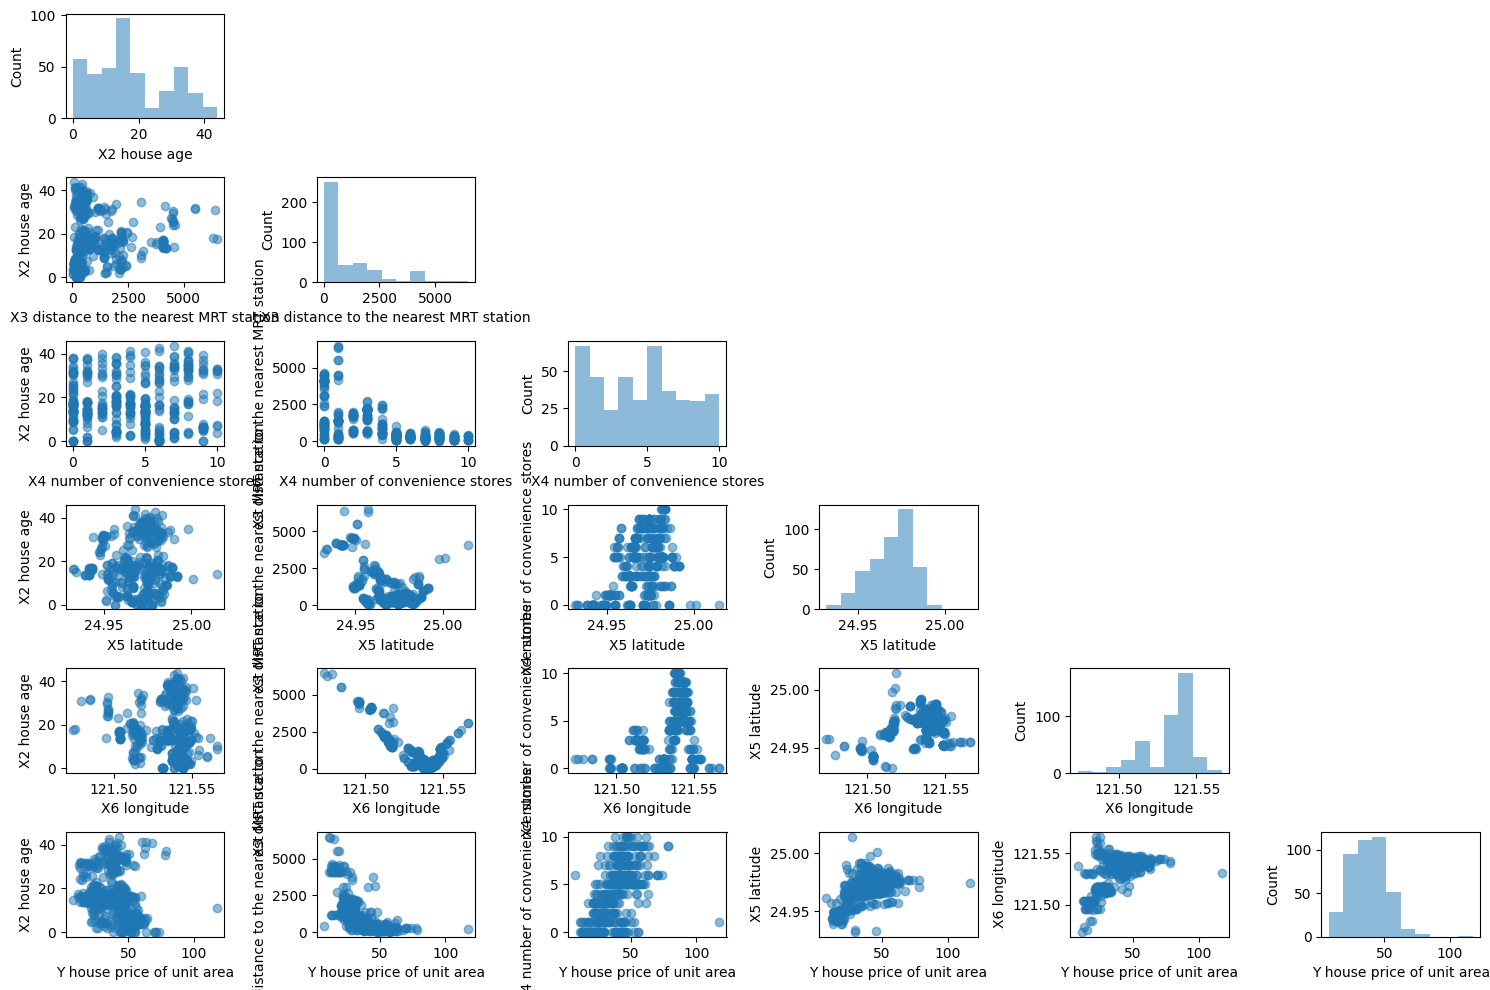

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.plotting import scatterplotmatrix
import numpy as np

# Carga del conjunto de datos
# Nota: Asegúrate de tener el archivo en el mismo directorio o proporcionar la ruta correcta
df = pd.read_excel('data/RealEstate.xlsx')

# Visualización inicial para conocer los nombres de las columnas
print(df.columns)
print(df.head())

# Selección de rasgos (rasgos numéricos relevantes para el precio)
# Basándonos en la estructura común de este dataset:
colElegidas = ['X2 house age', 'X3 distance to the nearest MRT station', 
               'X4 number of convenience stores', 'X5 latitude', 'X6 longitude', 'Y house price of unit area']


# Dibujamos las gráficas con los pares de rasgos
scatterplotmatrix(df[colElegidas].values, figsize=(15, 10),
                  names=colElegidas, alpha=0.5)
plt.tight_layout()
plt.show()

b) Dibuje la matriz de correlación. ¿Qué atributo es más prometedor para realizar una regresión lineal? ¿Cuál es menos prometedor en este sentido? Razone su respuesta.


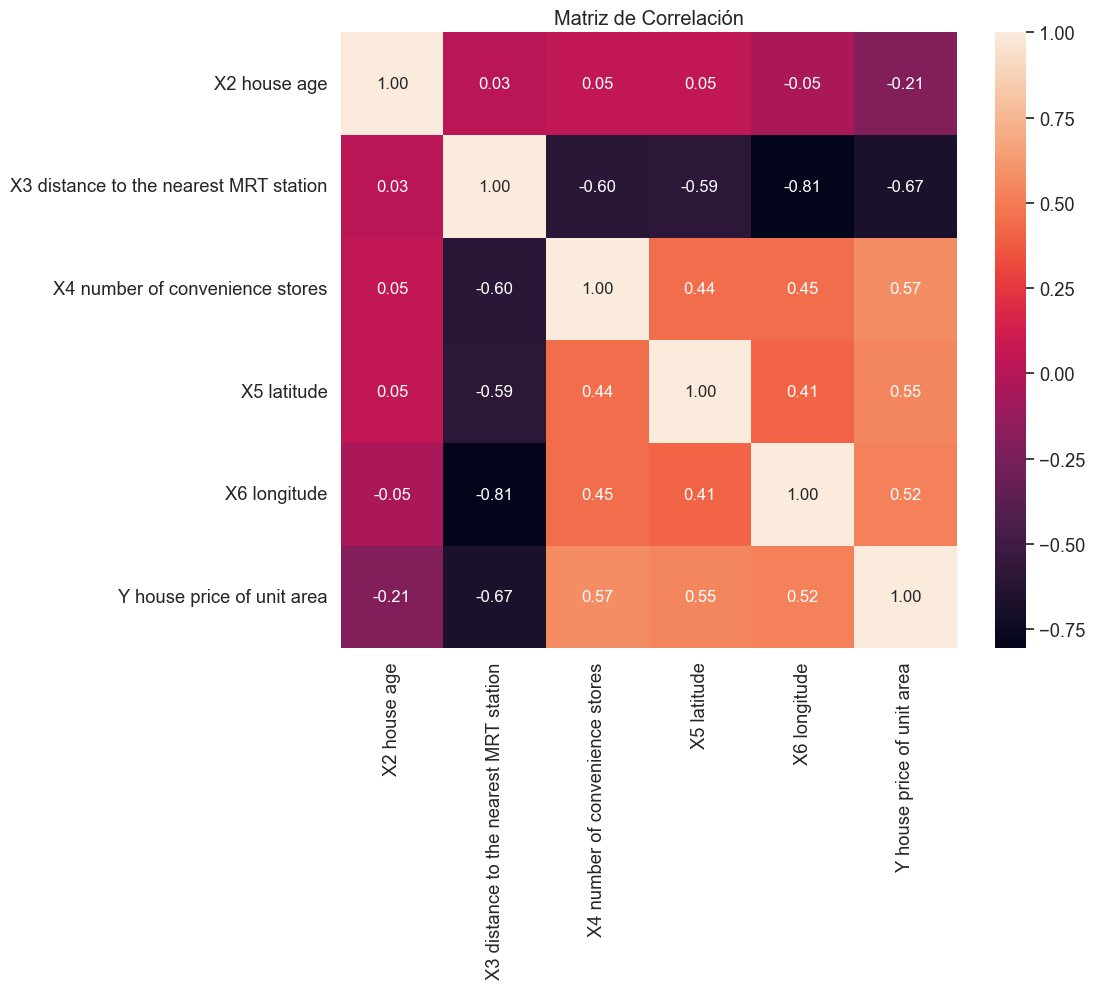

In [2]:
import seaborn as sns

# Cálculo de la matriz de correlación
cm = np.corrcoef(df[colElegidas].values.T)

# Dibujo del mapa de calor
plt.figure(figsize=(10, 8))
sns.set(font_scale=1.2)
hm = sns.heatmap(cm,
                 cbar=True,
                 annot=True,
                 square=True,
                 fmt='.2f',
                 annot_kws={'size': 12},
                 yticklabels=colElegidas,
                 xticklabels=colElegidas)
plt.title('Matriz de Correlación')
plt.show()

**Atributo más prometedor:**
El atributo más prometedor para realizar una regresión lineal es **`X3 distance to the nearest MRT station`** (distancia a la estación de MRT más cercana). Al observar la matriz de correlación, este atributo presenta el coeficiente de correlación de Pearson más alto en valor absoluto respecto a la variable objetivo (`Y house price of unit area`), con un valor de **-0.67**. Esto indica que existe una fuerte relación lineal inversa: a medida que disminuye la distancia a la estación, el precio de la vivienda tiende a aumentar. En el contexto de regresión lineal, buscamos variables predictoras con una alta correlación (fuerte dependencia lineal) con la variable respuesta, y este atributo es el mejor candidato.

**Atributo menos prometedor:**
El atributo menos prometedor es **`X2 house age`** (antigüedad de la casa). Su coeficiente de correlación con la variable objetivo es el más cercano a cero dentro del conjunto seleccionado, con un valor de **-0.21**. Un coeficiente de correlación tan bajo indica que la relación puramente *lineal* entre la edad de la casa y su precio es muy débil. Como vimos en los gráficos de dispersión, la relación parece ser no lineal (posiblemente en forma de "U"), por lo que un modelo de regresión lineal simple que utilice únicamente este atributo no sería capaz de predecir el precio con precisión sin aplicar transformaciones previas.

c) Escale los rasgos y realice una regresión lineal simple con el atributo más prometedor. ¿Obtiene un resultado adecuado? Razone su respuesta.

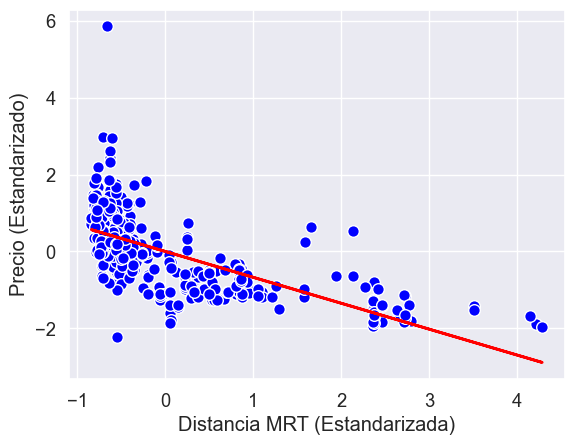

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Supongamos que el más prometedor es 'X3 distance to the nearest MRT station'
X_prometedor = df[['X3 distance to the nearest MRT station']].values
y = df['Y house price of unit area'].values

# Escalado
sc_x = StandardScaler()
sc_y = StandardScaler()
X_std = sc_x.fit_transform(X_prometedor)
y_std = sc_y.fit_transform(y[:, np.newaxis]).flatten()

# Regresión Lineal Simple
lr = LinearRegression()
lr.fit(X_std, y_std)

# Visualización de la regresión
plt.scatter(X_std, y_std, c='blue', edgecolor='white', s=70)
plt.plot(X_std, lr.predict(X_std), color='red', lw=2)
plt.xlabel('Distancia MRT (Estandarizada)')
plt.ylabel('Precio (Estandarizado)')
plt.show()

d) Elija un valor sin escalar del rasgo seleccionado en el apartado anterior y calcule el precio estimado para dicho valor.

In [4]:
# Valor de ejemplo: una distancia de 500 metros a la estación
valor_ejemplo = np.array([[500]])

# Escalar el valor de entrada
valor_ejemplo_std = sc_x.transform(valor_ejemplo)

# Predecir en la escala estandarizada
precio_std = lr.predict(valor_ejemplo_std)

# Transformación inversa para obtener el precio real
precio_real = sc_y.inverse_transform(precio_std.reshape(-1, 1))

print(f"Para una distancia de {valor_ejemplo[0][0]}, el precio estimado es: {precio_real[0][0]:.2f}")

Para una distancia de 500, el precio estimado es: 42.22


2) (2 ptos) Divida el conjunto de muestras “RealState.xlsx” en entrenamiento y test:

a) Utilice únicamente el conjunto de entrenamiento para entrenar mediante RANSAC una recta de regresión con el rasgo más prometedor del ejercicio anterior. Ajuste los hiperparámetros de RANSAC para que al menos haya 20 muestras seleccionadas durante el entrenamiento, es decir, que no sean atípicas.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RANSACRegressor, LinearRegression

# Definición de variables (usando el rasgo más prometedor del Ejercicio 1)
X = df[['X3 distance to the nearest MRT station']].values
y = df['Y house price of unit area'].values

# División en entrenamiento y test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0)

# Entrenamiento de RANSAC
# min_samples=20 asegura que se usen al menos 20 muestras para el modelo inicial
ransac = RANSACRegressor(LinearRegression(), 
                         max_trials=100, 
                         min_samples=20, 
                         loss='absolute_error', 
                         residual_threshold=10.0, 
                         random_state=0)
ransac.fit(X_train, y_train)

,"estimator estimator: object, default=NoneBase estimator object which implements the following methods:* `fit(X, y)`: Fit model to given training data and target values.* `score(X, y)`: Returns the mean accuracy on the given test data, which is used for the stop criterion defined by `stop_score`. Additionally, the score is used to decide which of two equally large consensus sets is chosen as the better one.* `predict(X)`: Returns predicted values using the linear model, which is used to compute residual error using loss function.If `estimator` is None, then:class:`~sklearn.linear_model.LinearRegression` is used fortarget values of dtype float.Note that the current implementation only supports regressionestimators.",LinearRegression()
,"min_samples min_samples: int (>= 1) or float ([0, 1]), default=NoneMinimum number of samples chosen randomly from original data. Treatedas an absolute number of samples for `min_samples >= 1`, treated as arelative number `ceil(min_samples * X.shape[0])` for`min_samples < 1`. This is typically chosen as the minimal number ofsamples necessary to estimate the given `estimator`. By default a:class:`~sklearn.linear_model.LinearRegression` estimator is assumed and`min_samples` is chosen as ``X.shape[1] + 1``. This parameter is highlydependent upon the model, so if a `estimator` other than:class:`~sklearn.linear_model.LinearRegression` is used, the user mustprovide a value.",20
,"residual_threshold residual_threshold: float, default=NoneMaximum residual for a data sample to be classified as an inlier.By default the threshold is chosen as the MAD (median absolutedeviation) of the target values `y`. Points whose residuals arestrictly equal to the threshold are considered as inliers.",10.0
,"is_data_valid is_data_valid: callable, default=NoneThis function is called with the randomly selected data before themodel is fitted to it: `is_data_valid(X, y)`. If its return value isFalse the current randomly chosen sub-sample is skipped.",None
,"is_model_valid is_model_valid: callable, default=NoneThis function is called with the estimated model and the randomlyselected data: `is_model_valid(model, X, y)`. If its return value isFalse the current randomly chosen sub-sample is skipped.Rejecting samples with this function is computationally costlier thanwith `is_data_valid`. `is_model_valid` should therefore only be used ifthe estimated model is needed for making the rejection decision.",None
,"max_trials max_trials: int, default=100Maximum number of iterations for random sample selection.",100
,"max_skips max_skips: int, default=np.infMaximum number of iterations that can be skipped due to finding zeroinliers or invalid data defined by ``is_data_valid`` or invalid modelsdefined by ``is_model_valid``... versionadded:: 0.19",inf
,"stop_n_inliers stop_n_inliers: int, default=np.infStop iteration if at least this number of inliers are found.",inf
,"stop_score stop_score: float, default=np.infStop iteration if score is greater equal than this threshold.",inf
,"stop_probability stop_probability: float in range [0, 1], default=0.99RANSAC iteration stops if at least one outlier-free set of the trainingdata is sampled in RANSAC. This requires to generate at least Nsamples (iterations):: N >= log(1 - probability) / log(1 - e**m)where the probability (confidence) is typically set to high value suchas 0.99 (the default) and e is the current fraction of inliers w.r.t.the total number of samples.",0.99
,"loss loss: str, callable, default='absolute_error'String inputs, 'absolute_error' and 'squared_error' are supported whichfind the absolute error and squared error per sample respectively.If ``loss`` is a callable, then it should be a function that takestwo arrays as inputs, the true and predicted value and returns a 1-Darray with the i-th value of the array corresponding to the losson ``X[i]``.If the loss on a sample is greater than the ``residual_threshold``,then this sample is classified as an outlier... versionadded:: 0.18",'

b) Dibuje la recta de regresión resultante donde se observen las muestras típicas y las atípicas del conjunto de entrenamiento en colores diferentes.

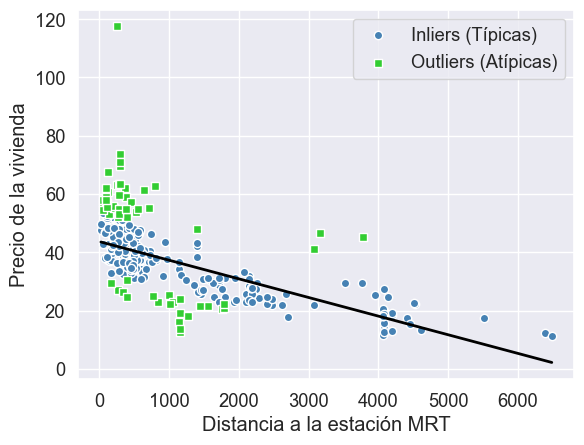

In [6]:
import numpy as np

inlier_mask = ransac.inlier_mask_
outlier_mask = np.logical_not(inlier_mask)

# Puntos para dibujar la recta
line_X = np.arange(X_train.min(), X_train.max())[:, np.newaxis]
line_y_ransac = ransac.predict(line_X)

plt.scatter(X_train[inlier_mask], y_train[inlier_mask],
            c='steelblue', edgecolor='white', 
            marker='o', label='Inliers (Típicas)')
plt.scatter(X_train[outlier_mask], y_train[outlier_mask],
            c='limegreen', edgecolor='white', 
            marker='s', label='Outliers (Atípicas)')
plt.plot(line_X, line_y_ransac, color='black', lw=2)

plt.xlabel('Distancia a la estación MRT')
plt.ylabel('Precio de la vivienda')
plt.legend(loc='upper right')
plt.show()

c) Ahora considere tanto el conjunto de entrenamiento como el de test y dibuje la nube de residuos correspondiente para ambos conjuntos.

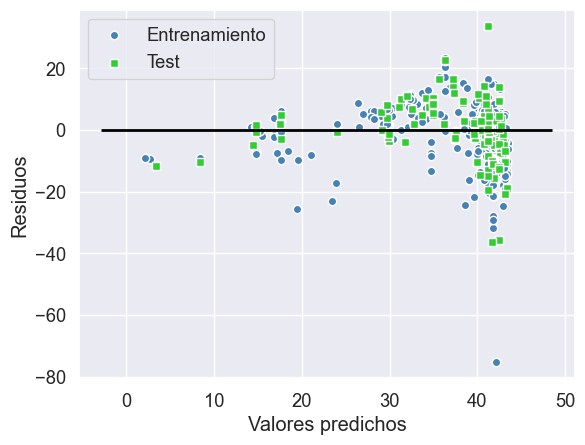

In [7]:
# Predicciones
y_train_pred = ransac.predict(X_train)
y_test_pred = ransac.predict(X_test)

# Gráfico de residuos
plt.scatter(y_train_pred, y_train_pred - y_train,
            c='steelblue', marker='o', edgecolor='white',
            label='Entrenamiento')
plt.scatter(y_test_pred, y_test_pred - y_test,
            c='limegreen', marker='s', edgecolor='white',
            label='Test')

plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.legend(loc='upper left')
plt.hlines(y=0, xmin=y_train_pred.min()-5, xmax=y_train_pred.max()+5, color='black', lw=2)
plt.show()

d) Observando la nube de residuos, ¿qué rango de valores predichos suelen ser más fiables en este modelo?

Los valores predichos en el rango de 0 a 25 son los más fiables. En este tramo, los residuos se mantienen agrupados y muy cercanos a cero (menor error). Por el contrario, a partir de valores predichos de 30, la nube se dispersa drásticamente formando un embudo con grandes residuos negativos. Esto ocurre porque RANSAC descartó las casas más caras al entrenar, provocando que el modelo subestime sistemáticamente las propiedades de alto valor.

e) Calcule el ECM y el coeficiente de determinación del modelo en entrenamiento y en test.

In [8]:
from sklearn.metrics import mean_squared_error, r2_score

# Cálculo de métricas
mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
r2_train = r2_score(y_train, y_train_pred)
r2_test = r2_score(y_test, y_test_pred)

print(f'ECM entrenamiento: {mse_train:.3f}, test: {mse_test:.3f}')
print(f'R^2 entrenamiento: {r2_train:.3f}, test: {r2_test:.3f}')

ECM entrenamiento: 108.302, test: 92.738
R^2 entrenamiento: 0.431, test: 0.456


3) (1.5 ptos) Divida el conjunto de muestras “RealState.xlsx” en entrenamiento y test:

a) Realice una regresión múltiple con todos los rasgos y calcule el ECM y el coeficiente de determinación del modelo en entrenamiento y en test.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Definición de todos los rasgos de entrada y la variable objetivo
X_multiple = df[['X1 transaction date', 'X2 house age', 
                 'X3 distance to the nearest MRT station', 
                 'X4 number of convenience stores', 
                 'X5 latitude', 'X6 longitude']].values
y = df['Y house price of unit area'].values

# División en entrenamiento y test (manteniendo la proporción 70/30)
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiple, y, test_size=0.3, random_state=0)

# Entrenamiento del modelo de regresión múltiple
slr = LinearRegression()
slr.fit(X_train_m, y_train_m)

# Predicciones
y_train_pred = slr.predict(X_train_m)
y_test_pred = slr.predict(X_test_m)

# Cálculo de métricas
print('--- Regresión Múltiple (Todos los rasgos) ---')
print(f'ECM entrenamiento: {mean_squared_error(y_train_m, y_train_pred):.3f}')
print(f'ECM test: {mean_squared_error(y_test_m, y_test_pred):.3f}')
print(f'R^2 entrenamiento: {r2_score(y_train_m, y_train_pred):.3f}')
print(f'R^2 test: {r2_score(y_test_m, y_test_pred):.3f}')

--- Regresión Múltiple (Todos los rasgos) ---
ECM entrenamiento: 79.874
ECM test: 71.576
R^2 entrenamiento: 0.581
R^2 test: 0.580


b) Aplique un esquema de regularización de manera que se ignoren dos de los rasgos, es decir, que queden cuatro rasgos. Con este esquema, entrene un modelo de regresión lineal múltiple y calcule el ECM y el coeficiente de determinación en entrenamiento y en test.

In [ ]:
from sklearn.linear_model import Lasso

sc_x_m = StandardScaler()
X_train_m_std = sc_x_m.fit_transform(X_train_m)
X_test_m_std = sc_x_m.transform(X_test_m)

# Aplicamos Lasso. Ajustamos alpha para obtener 4 coeficientes distintos de cero, primero probé con alpha=1 y solo puso a cero 1 coeficiente y finalmente con alpha=1.5 conseguimos el resultado esperado
lasso = Lasso(alpha=1.5) 
lasso.fit(X_train_m_std, y_train_m)

y_train_lasso_pred = lasso.predict(X_train_m_std)
y_test_lasso_pred = lasso.predict(X_test_m_std)

# Visualización de los coeficientes para identificar los rasgos ignorados
feature_names = ['Fecha', 'Antigüedad', 'Distancia MRT', 'Tiendas', 'Latitud', 'Longitud']
for name, coef in zip(feature_names, lasso.coef_):
    print(f'Rasgo: {name:15} | Coeficiente: {coef:.4f}')

# Cálculo de métricas del modelo Lasso
print('\n--- Regresión Lasso (4 rasgos activos) ---')
print(f'ECM entrenamiento: {mean_squared_error(y_train_m, y_train_lasso_pred):.3f}')
print(f'ECM test: {mean_squared_error(y_test_m, y_test_lasso_pred):.3f}')
print(f'R^2 entrenamiento: {r2_score(y_train_m, y_train_lasso_pred):.3f}')
print(f'R^2 test: {r2_score(y_test_m, y_test_lasso_pred):.3f}')

Rasgo: Fecha           | Coeficiente: 0.0000
Rasgo: Antigüedad      | Coeficiente: -1.6536
Rasgo: Distancia MRT   | Coeficiente: -5.1257
Rasgo: Tiendas         | Coeficiente: 2.1877
Rasgo: Latitud         | Coeficiente: 2.1400
Rasgo: Longitud        | Coeficiente: 0.0000

--- Regresión Lasso (4 rasgos activos) ---
ECM entrenamiento: 87.542
ECM test: 78.232
R^2 entrenamiento: 0.540
R^2 test: 0.541


c) Considerando los resultados del apartado anterior, ¿qué es menos relevante, la fecha de compra, la antigüedad, la distancia a la estación, la cercanía de tiendas o la posición de la vivienda?

Lo menos relevante es la fecha de compra y parte de la posición de la vivienda (la longitud). Al aplicar la regularización Lasso, el modelo asigna un coeficiente exactamente de 0.0000 a ambos atributos. Esto indica que son los que menos información predictiva aportan al precio, por lo que el algoritmo los descarta por completo.

4) (1 pto) Divida el conjunto de muestras “RealState.xlsx” en entrenamiento y test:

a) Aplique un árbol de regresión utilizando el rasgo más prometedor. La profundidad del árbol será tal que sólo sea necesario hacer dos preguntas.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Definición de variables (usando el rasgo más prometedor: Distancia a estación MRT)[cite: 1, 2]
X = df[['X3 distance to the nearest MRT station']].values
y = df['Y house price of unit area'].values

# División en entrenamiento y test[cite: 1, 2]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0)

# Árbol de regresión con profundidad 2
tree = DecisionTreeRegressor(max_depth=2)
tree.fit(X_train, y_train)


,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",2
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_le

b) Dibuje en un gráfico las muestras de entrenamiento y test y la regresión.

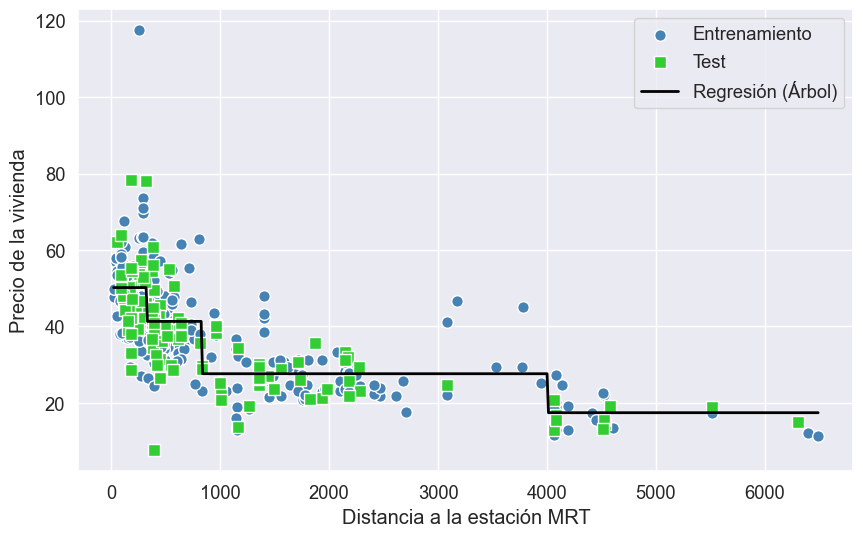

In [ ]:
sort_idx = X_train.flatten().argsort()
X_range = np.linspace(X.min(), X.max(), 500)[:, np.newaxis]

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, c='steelblue', edgecolor='white', s=70, label='Entrenamiento')
plt.scatter(X_test, y_test, c='limegreen', edgecolor='white', s=70, marker='s', label='Test')
plt.plot(X_range, tree.predict(X_range), color='black', lw=2, label='Regresión (Árbol)')

plt.xlabel('Distancia a la estación MRT')
plt.ylabel('Precio de la vivienda')
plt.legend()
plt.show()

c) Calcule el ECM y el coeficiente de determinación en entrenamiento y test.

In [13]:
# c) Cálculo de métricas[cite: 1]
y_train_pred = tree.predict(X_train)
y_test_pred = tree.predict(X_test)

print(f'ECM entrenamiento: {mean_squared_error(y_train, y_train_pred):.3f}')
print(f'ECM test: {mean_squared_error(y_test, y_test_pred):.3f}')
print(f'R^2 entrenamiento: {r2_score(y_train, y_train_pred):.3f}')
print(f'R^2 test: {r2_score(y_test, y_test_pred):.3f}')

ECM entrenamiento: 76.976
ECM test: 66.038
R^2 entrenamiento: 0.596
R^2 test: 0.613


### EJERCICIO AVANZADO
5) (2 ptos) Divida el conjunto de muestras “RealState.xlsx” en entrenamiento y test. Considere todos los pares de rasgos de entrada posibles (incluyendo los casos en los que un rasgo se empareja consigo mismo):

a) Realice una regresión lineal múltiple y calcule el ECM y el coeficiente de determinación del modelo en entrenamiento y en test, para cada par de rasgos de entrada. Dibuje cuatro figuras mostrando los resultados mediante matrices con colores. Cada figura debe ser similar a ésta:<br>
<p align="center">
  <img src="img/img1.png" alt="Descripción" width="500" height="500">
</p>


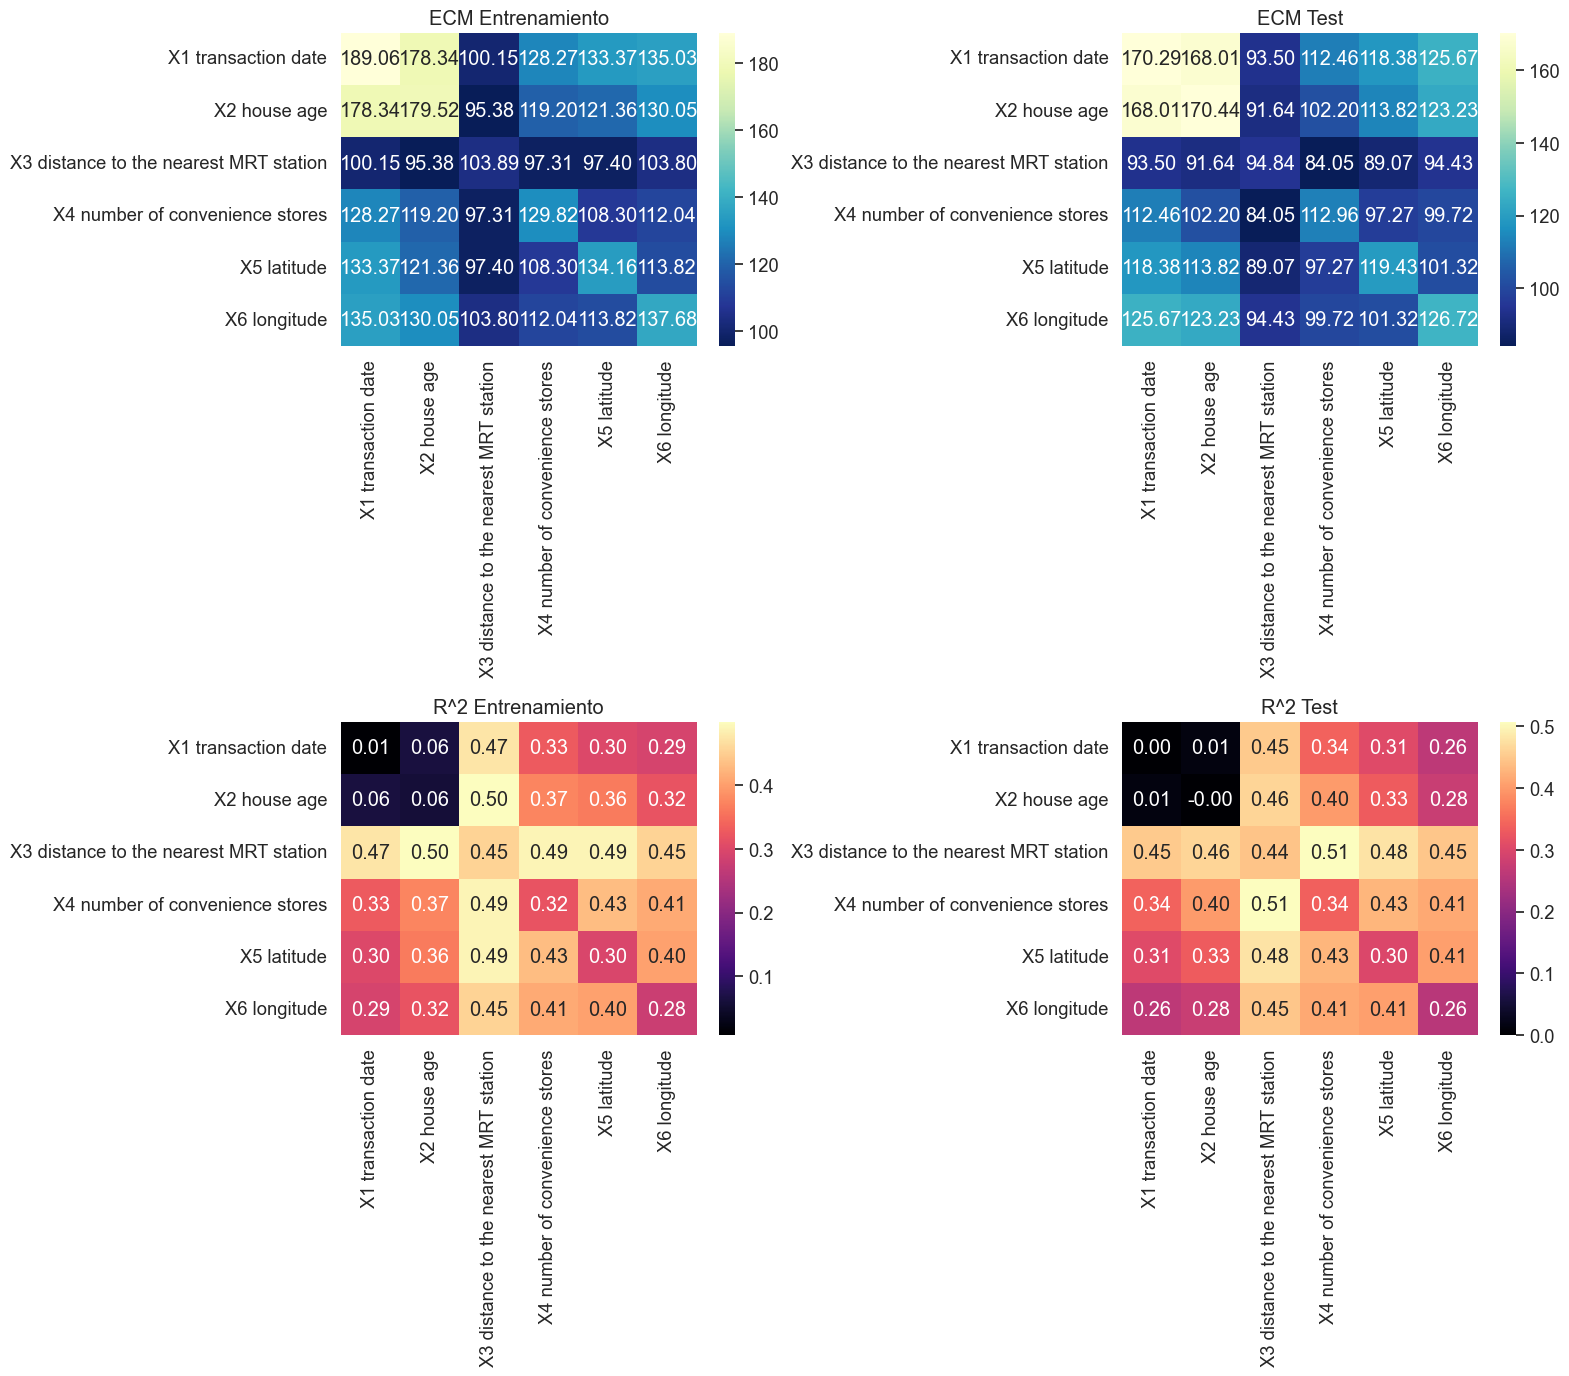

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Carga y preparación de datos
df = pd.read_excel('data/RealEstate.xlsx')
X_cols = ['X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 
          'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']
y = df['Y house price of unit area'].values
n = len(X_cols)

# Matrices para almacenar métricas[cite: 2]
mse_train_map = np.zeros((n, n))
mse_test_map = np.zeros((n, n))
r2_train_map = np.zeros((n, n))
r2_test_map = np.zeros((n, n))

# Bucle para evaluar todos los pares posibles[cite: 1, 2]
for i in range(n):
    for j in range(n):
        # Selección del par de rasgos (incluye emparejarse consigo mismo)[cite: 2]
        X_pair = df[[X_cols[i], X_cols[j]]].values
        X_train, X_test, y_train, y_test = train_test_split(X_pair, y, test_size=0.3, random_state=0)
        
        # Entrenamiento del modelo[cite: 1]
        lr = LinearRegression()
        lr.fit(X_train, y_train)
        
        # Predicciones y cálculo de métricas[cite: 1, 2]
        y_train_pred = lr.predict(X_train)
        y_test_pred = lr.predict(X_test)
        
        mse_train_map[i, j] = mean_squared_error(y_train, y_train_pred)
        mse_test_map[i, j] = mean_squared_error(y_test, y_test_pred)
        r2_train_map[i, j] = r2_score(y_train, y_train_pred)
        r2_test_map[i, j] = r2_score(y_test, y_test_pred)

# Dibujo de las cuatro figuras de resultados[cite: 2]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
metrics = [mse_train_map, mse_test_map, r2_train_map, r2_test_map]
titles = ['ECM Entrenamiento', 'ECM Test', 'R^2 Entrenamiento', 'R^2 Test']
palettes = ['YlGnBu_r', 'YlGnBu_r', 'magma', 'magma']

for ax, mat, title, cp in zip(axes.flat, metrics, titles, palettes):
    sns.heatmap(mat, annot=True, fmt=".2f", cmap=cp, ax=ax,
                xticklabels=X_cols, yticklabels=X_cols)
    ax.set_title(title)

plt.tight_layout()
plt.show()

b) Explique en detalle y dando el razonamiento, qué pareja(s) de rasgos sería(n) más apropiada(s) para realizar la regresión en este conjunto de datos.

La pareja más apropiada es la formada por X3 distance to the nearest MRT station y X4 number of convenience stores. Observando las matrices de resultados para el conjunto de Test, esta intersección es la que obtiene el rendimiento óptimo: alcanza el coeficiente de determinación (R^2) más alto de toda la matriz (0.51) y, simultáneamente, el Error Cuadrático Medio (ECM) más bajo (84.05).

c) Con la pareja de rasgos seleccionada en el apartado anterior, haga una regresión lineal múltiple y genere una gráfica bidimensional en la que los ejes X y Y sean los rasgos seleccionados, y el color indique la variable predicha (el precio). Debe dibujar la estimación del regresor mediante una matriz coloreada, y las muestras de entrenamiento como una nube de puntos coloreados. Añada una barra de color para poder interpretar los colores como valores de la variable predicha. El resultado debe ser similar a éste:
<p align="center">
  <img src="img/img2.png" alt="Descripción" width="500" height="500">
</p>


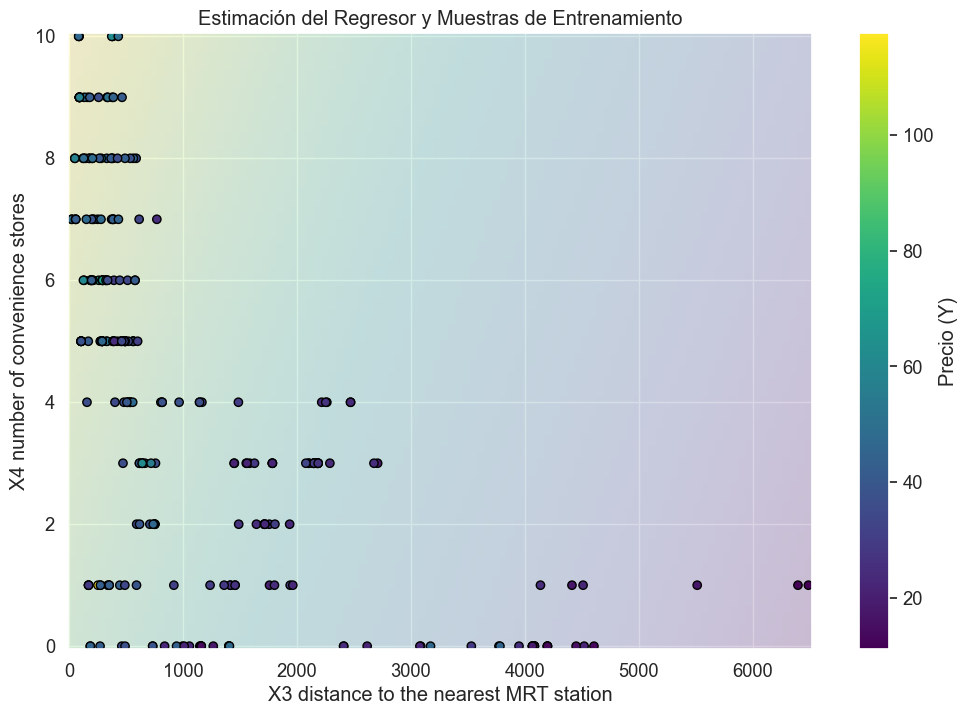

In [15]:
# Selección de la mejor pareja de rasgos[cite: 2]
best_features = ['X3 distance to the nearest MRT station', 'X4 number of convenience stores']
X_best = df[best_features].values
X_train, X_test, y_train, y_test = train_test_split(X_best, y, test_size=0.3, random_state=0)

# Entrenamiento del modelo final[cite: 1, 2]
lr_best = LinearRegression()
lr_best.fit(X_train, y_train)

# Creación de la malla (grid) para la superficie de estimación[cite: 2]
x_min, x_max = X_best[:, 0].min(), X_best[:, 0].max()
y_min, y_max = X_best[:, 1].min(), X_best[:, 1].max()
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

# Predicción sobre la malla[cite: 1, 2]
Z = lr_best.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Generación de la gráfica[cite: 2]
plt.figure(figsize=(12, 8))
# Dibujo de la estimación del regresor (matriz coloreada)
plt.pcolormesh(xx, yy, Z, cmap='viridis', shading='auto', alpha=0.2)
# Dibujo de las muestras de entrenamiento
scatter = plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='viridis', edgecolor='black')

# Configuración de elementos visuales
plt.colorbar(scatter, label='Precio (Y)')
plt.xlabel(best_features[0])
plt.ylabel(best_features[1])
plt.title('Estimación del Regresor y Muestras de Entrenamiento')
plt.show()

d) ¿Para qué valores de los dos rasgos de entrada se observa un mayor error? Explique y justifique su respuesta en detalle.

El mayor error se observa para valores muy bajos de X3 (distancia cercana a 0) y valores muy altos de X4 (de 6 a 10 tiendas), es decir, en la esquina superior izquierda de la gráfica. En esa zona, el fondo coloreado de la regresión (la predicción) es de un tono verde amarillento claro, lo que indica que el modelo predice precios muy altos (entre 80 y 100). Sin embargo, se pueden observar muchos puntos de datos (las muestras reales) de color azul oscuro y morado en esa misma área. Esto significa que sus precios reales son mucho más bajos (entre 20 y 40). Por tanto, en esta zona el regresor lineal comete un gran error al sobreestimar drásticamente el valor de esas viviendas.

### EJERCICIO EXPERTO
6) (2 ptos) Divida el conjunto de muestras “RealState.xlsx” en entrenamiento y test. Considere todos los rasgos de entrada:

a) Entrene un árbol de regresión para valores del hiperparámetro max_depth entre 1 y 6, ambos inclusive. Calcule el ECM y el coeficiente de determinación del modelo en entrenamiento y en test. Dibuje dos figuras, una para el ECM y otra para el coeficiente de determinación. En cada figura debe mostrar una serie de datos para el rendimiento en entrenamiento, y otra serie de datos para el rendimiento en test. El eje horizontal será el valor del hiperparámetro, y el eje vertical el valor de la medida de rendimiento.

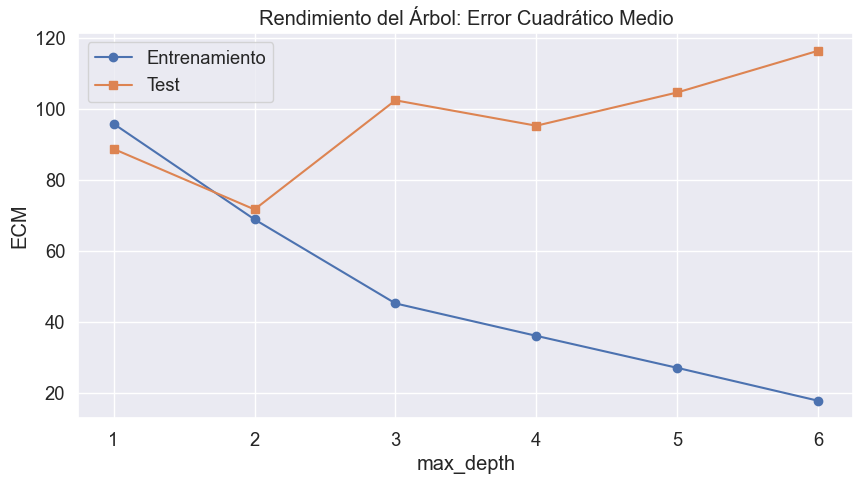

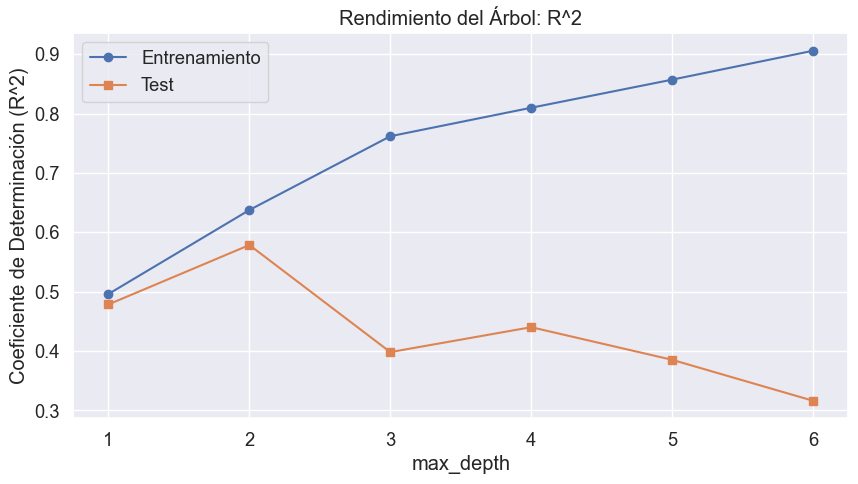

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Preparación de datos con todos los rasgos[cite: 1, 2]
X_all = df[['X1 transaction date', 'X2 house age', 'X3 distance to the nearest MRT station', 
            'X4 number of convenience stores', 'X5 latitude', 'X6 longitude']].values
y = df['Y house price of unit area'].values

X_train, X_test, y_train, y_test = train_test_split(X_all, y, test_size=0.3, random_state=0)

# Listas para almacenar resultados
depths = np.arange(1, 7)
mse_train, mse_test = [], []
r2_train, r2_test = [], []

# Entrenamiento y cálculo de métricas para cada profundidad[cite: 2]
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=0)
    tree.fit(X_train, y_train)
    
    y_tr_pred = tree.predict(X_train)
    y_te_pred = tree.predict(X_test)
    
    mse_train.append(mean_squared_error(y_train, y_tr_pred))
    mse_test.append(mean_squared_error(y_test, y_te_pred))
    r2_train.append(r2_score(y_train, y_tr_pred))
    r2_test.append(r2_score(y_test, y_te_pred))

# Gráfica del ECM[cite: 2]
plt.figure(figsize=(10, 5))
plt.plot(depths, mse_train, label='Entrenamiento', marker='o')
plt.plot(depths, mse_test, label='Test', marker='s')
plt.xlabel('max_depth')
plt.ylabel('ECM')
plt.title('Rendimiento del Árbol: Error Cuadrático Medio')
plt.legend()
plt.grid(True)
plt.show()

# Gráfica del R^2[cite: 2]
plt.figure(figsize=(10, 5))
plt.plot(depths, r2_train, label='Entrenamiento', marker='o')
plt.plot(depths, r2_test, label='Test', marker='s')
plt.xlabel('max_depth')
plt.ylabel('Coeficiente de Determinación (R^2)')
plt.title('Rendimiento del Árbol: R^2')
plt.legend()
plt.grid(True)
plt.show()

b) Explique en detalle y dando el razonamiento, qué valor(es) del hiperparámetro max_depth sería(n) más apropiado(s) para realizar la regresión en este conjunto de datos.

El valor más apropiado es max_depth = 2. Al observar las primeras gráficas, en la profundidad 2 se alcanza el pico máximo de $R^2$ (cerca de 0.6) y el punto más bajo de ECM para el conjunto de Test. A partir de la profundidad 3, el rendimiento en Entrenamiento sigue mejorando, pero en Test empeora drásticamente (las líneas naranja y azul se separan), lo que es un claro indicador de sobreajuste (overfitting).

c) Entrene un árbol de regresión para valores del hiperparámetro min_samples_leaf entre 0.01 y 0.99, ambos inclusive. Calcule el ECM y el coeficiente de determinación del modelo en entrenamiento y en test. Dibuje dos figuras, una para el ECM y otra para el coeficiente de determinación. En cada figura debe mostrar una serie de datos para el rendimiento en entrenamiento, y otra serie de datos para el rendimiento en test. El eje horizontal será el valor del hiperparámetro, y el eje vertical el valor de la medida de rendimiento.

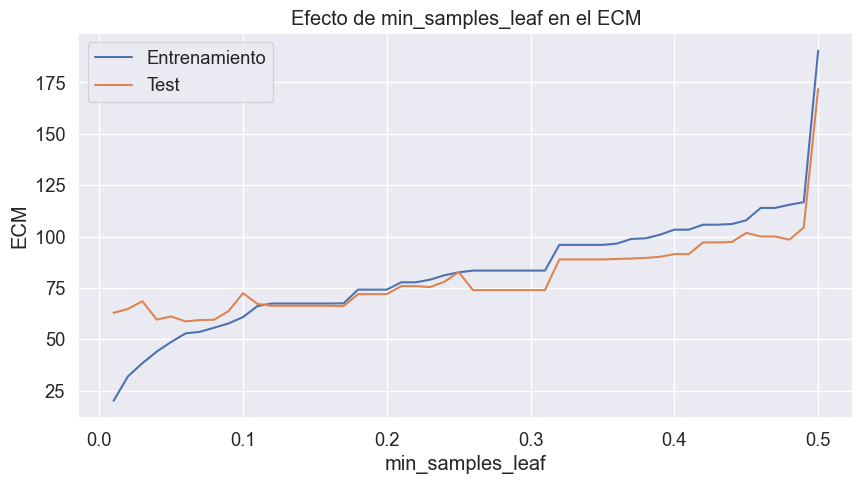

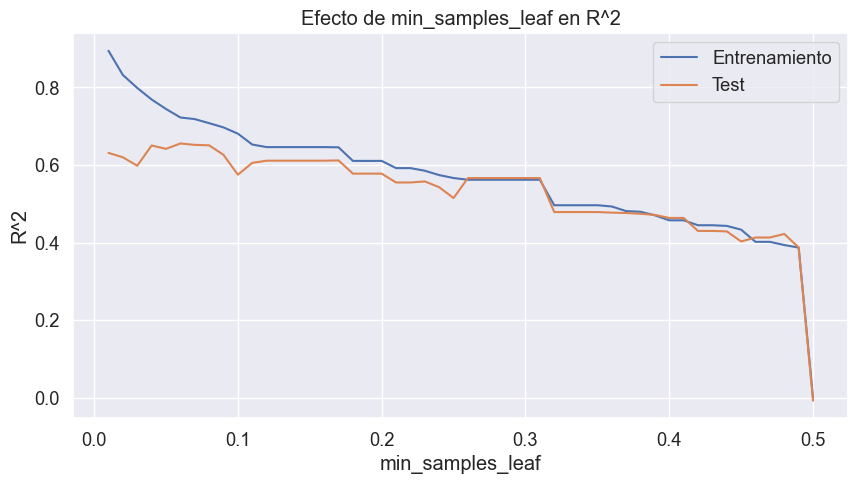

In [17]:
# Listas para almacenar resultados
# Usamos un rango de 0.01 a 0.5 para que la gráfica sea interpretable (más allá de 0.5 el árbol no divide)[cite: 2]
leaves = np.linspace(0.01, 0.5, 50) 
mse_train_l, mse_test_l = [], []
r2_train_l, r2_test_l = [], []

# Entrenamiento y cálculo de métricas[cite: 2]
for l in leaves:
    tree = DecisionTreeRegressor(min_samples_leaf=l, random_state=0)
    tree.fit(X_train, y_train)
    
    y_tr_pred = tree.predict(X_train)
    y_te_pred = tree.predict(X_test)
    
    mse_train_l.append(mean_squared_error(y_train, y_tr_pred))
    mse_test_l.append(mean_squared_error(y_test, y_te_pred))
    r2_train_l.append(r2_score(y_train, y_tr_pred))
    r2_test_l.append(r2_score(y_test, y_te_pred))

# Gráfica del ECM para min_samples_leaf[cite: 2]
plt.figure(figsize=(10, 5))
plt.plot(leaves, mse_train_l, label='Entrenamiento')
plt.plot(leaves, mse_test_l, label='Test')
plt.xlabel('min_samples_leaf')
plt.ylabel('ECM')
plt.title('Efecto de min_samples_leaf en el ECM')
plt.legend()
plt.grid(True)
plt.show()

# Gráfica del R^2 para min_samples_leaf[cite: 2]
plt.figure(figsize=(10, 5))
plt.plot(leaves, r2_train_l, label='Entrenamiento')
plt.plot(leaves, r2_test_l, label='Test')
plt.xlabel('min_samples_leaf')
plt.ylabel('R^2')
plt.title('Efecto de min_samples_leaf en R^2')
plt.legend()
plt.grid(True)
plt.show()

d) Explique en detalle y dando el razonamiento, qué valor(es) del hiperparámetro min_samples_leaf sería(n) más apropiado(s) para realizar la regresión en este conjunto de datos.

El valor más apropiado está en el rango de 0.05 a 0.08 (aproximadamente). En este tramo del eje horizontal es donde la curva de Test alcanza su mejor rendimiento generalizado (el pico más alto de $R^2$ y un ECM bajo y estable). Valores más cercanos a 0 provocan sobreajuste (la línea de entrenamiento es mucho mejor que la de test), mientras que a partir de 0.1 ambas curvas empiezan a empeorar paulatinamente, indicando que el modelo se vuelve demasiado simple (underfitting).